# YOLOv8 端到端偵測器 — HRIPCB
### `notebooks/03_yolo_detection.ipynb` · pcb-aoi · Stage 3

前兩個 stage 是**兩階段**(propose → classify):Stage 1 傳統 CV 提 proposals、
Stage 2 CNN 分類。end-to-end mAP 被 Stage 1 的 **proposal recall** 綁住 ——
最明顯的是 `short`(Stage 2 仍只有 36.2% AP,因為一半的 short 在 proposal 階段
就漏抓)。

**Stage 3 改用 YOLOv8n 端到端**:單一網路同時學定位 + 分類,不依賴外部
proposals,目標突破 recall 瓶頸、救起 `short`。

程式:[`src/voc_to_yolo.py`](../src/voc_to_yolo.py)、
[`src/train_yolo.py`](../src/train_yolo.py)、
[`src/evaluate_yolo.py`](../src/evaluate_yolo.py)。

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if (Path.cwd() / "03_yolo_detection.ipynb").exists() else Path.cwd()
if not (ROOT / "src").exists():
    ROOT = Path(r"D:\ash-portfolio\pcb-aoi")
sys.path.insert(0, str(ROOT))
from IPython.display import Image, display
import pandas as pd
from src.hripcb import CLASSES, CLASS_ZH
FIG = ROOT / "results" / "figures"

## 1. 為何端到端?

| | 兩階段 (Stage 1+2) | 端到端 (Stage 3) |
|---|---|---|
| 定位 | Stage 1 差影 + 形態學 | YOLO 直接回歸 bbox |
| 分類 | 獨立的 CNN | YOLO 同一網路 |
| 瓶頸 | proposal recall(漏抓即無救) | 無外部 proposal 依賴 |
| 代表受害類 | `short`(漏抓一半) | — |

YOLOv8n:3M 參數、anchor-free、單次前向同時輸出框與類別。

## 2. 訓練過程(ultralytics 自動產出)

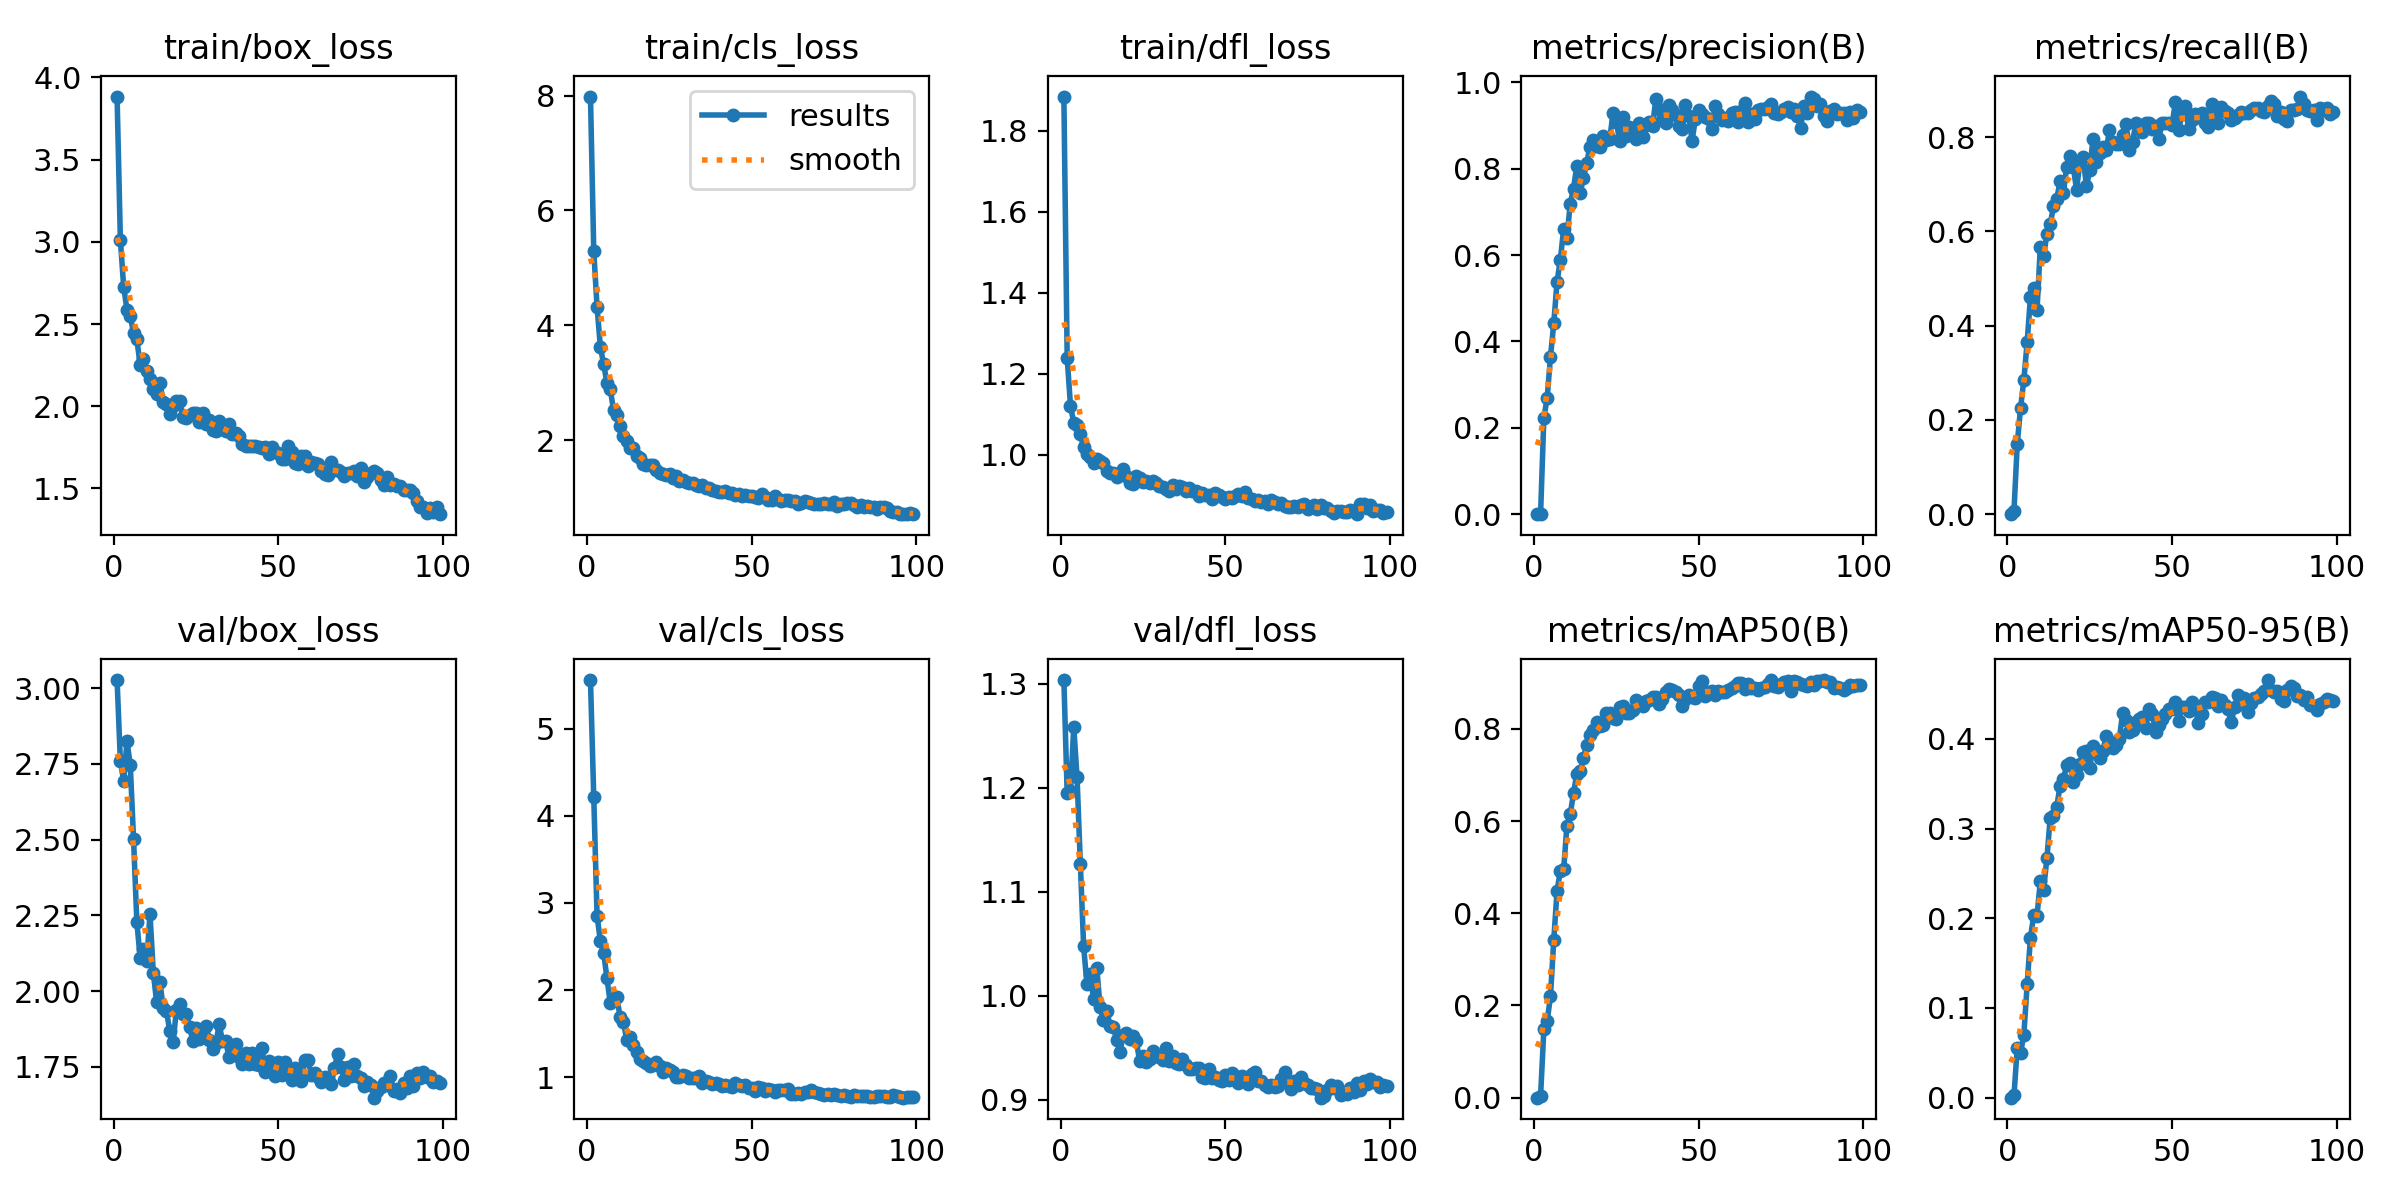

In [2]:
display(Image(filename=str(FIG / "03_training_curves.png")))

## 3. 三方法對比(本專案 narrative 核心)

三個 stage 都在**相同 test split(108 張影像、seed=42)**評估,可直接比較。

In [3]:
trad = json.loads((ROOT / "results" / "traditional_eval_summary.json").read_text())
clf = json.loads((ROOT / "results" / "classifier_eval_summary.json").read_text())
yolo = json.loads((ROOT / "results" / "yolo_eval_summary.json").read_text())

comp = pd.DataFrame([
    {"方法": "Stage 1:傳統 CV", "mAP@0.5": f"{trad['mAP@0.5']*100:.1f}%",
     "推論時間": f"{trad['timing']['mean_s_per_image']:.2f} s", "備註": "hand-crafted feature 撞牆"},
    {"方法": "Stage 2:R-CNN 風格 (proposals+CNN)", "mAP@0.5": f"{clf['end_to_end']['cnn']['mAP@0.5']*100:.1f}%",
     "推論時間": "Stage1 + CNN", "備註": "proposal recall 綁住 short"},
    {"方法": "Stage 3:YOLOv8n 端到端", "mAP@0.5": f"{yolo['mAP@0.5']*100:.1f}%",
     "推論時間": f"{yolo['ms_per_image']:.0f} ms", "備註": "端到端,無 proposal 依賴"},
])
comp

,方法,mAP@0.5,推論時間,備註
0,Stage 1:傳統 CV,27.4%,0.79 s,hand-crafted feature 撞牆
1,Stage 2:R-CNN 風格 (proposals+CNN),84.8%,Stage1 + CNN,proposal recall 綁住 short
2,Stage 3:YOLOv8n 端到端,91.8%,133 ms,"端到端,無 proposal 依賴"


In [4]:
# per-class AP@0.5 三方法並排,特別看 short
rows = []
for c in CLASSES:
    rows.append({"class": c, "中文": CLASS_ZH[c],
                 "S1 AP": round(trad["per_class"][c]["ap"], 3),
                 "S2 AP (e2e)": round(clf["end_to_end"]["cnn"]["per_class"][c]["ap"], 3),
                 "S3 AP (YOLO)": round(yolo["per_class_ap50"][c], 3)})
df = pd.DataFrame(rows)
print(f"YOLO mAP@0.5 = {yolo['mAP@0.5']*100:.1f}%  |  mAP@0.5:0.95 = {yolo['mAP@0.5:0.95']*100:.1f}%")
print(f"short: Stage1 {trad['per_class']['short']['ap']*100:.1f}%  ->  "
      f"Stage2 {clf['end_to_end']['cnn']['per_class']['short']['ap']*100:.1f}%  ->  "
      f"Stage3 {yolo['per_class_ap50']['short']*100:.1f}%")
df

YOLO mAP@0.5 = 91.8%  |  mAP@0.5:0.95 = 46.7%
short: Stage1 16.0%  ->  Stage2 36.2%  ->  Stage3 97.5%


,class,中文,S1 AP,S2 AP (e2e),S3 AP (YOLO)
0,missing_hole,缺孔,0.898,0.939,0.983
1,mouse_bite,鼠咬(缺口),0.049,0.948,0.889
2,open_circuit,斷路,0.024,0.941,0.861
3,short,短路,0.160,0.362,0.975
4,spur,毛刺(凸尖),0.019,0.912,0.926
5,spurious_copper,多餘銅(殘銅),0.496,0.983,0.873


### 3.1 PR 曲線與混淆矩陣

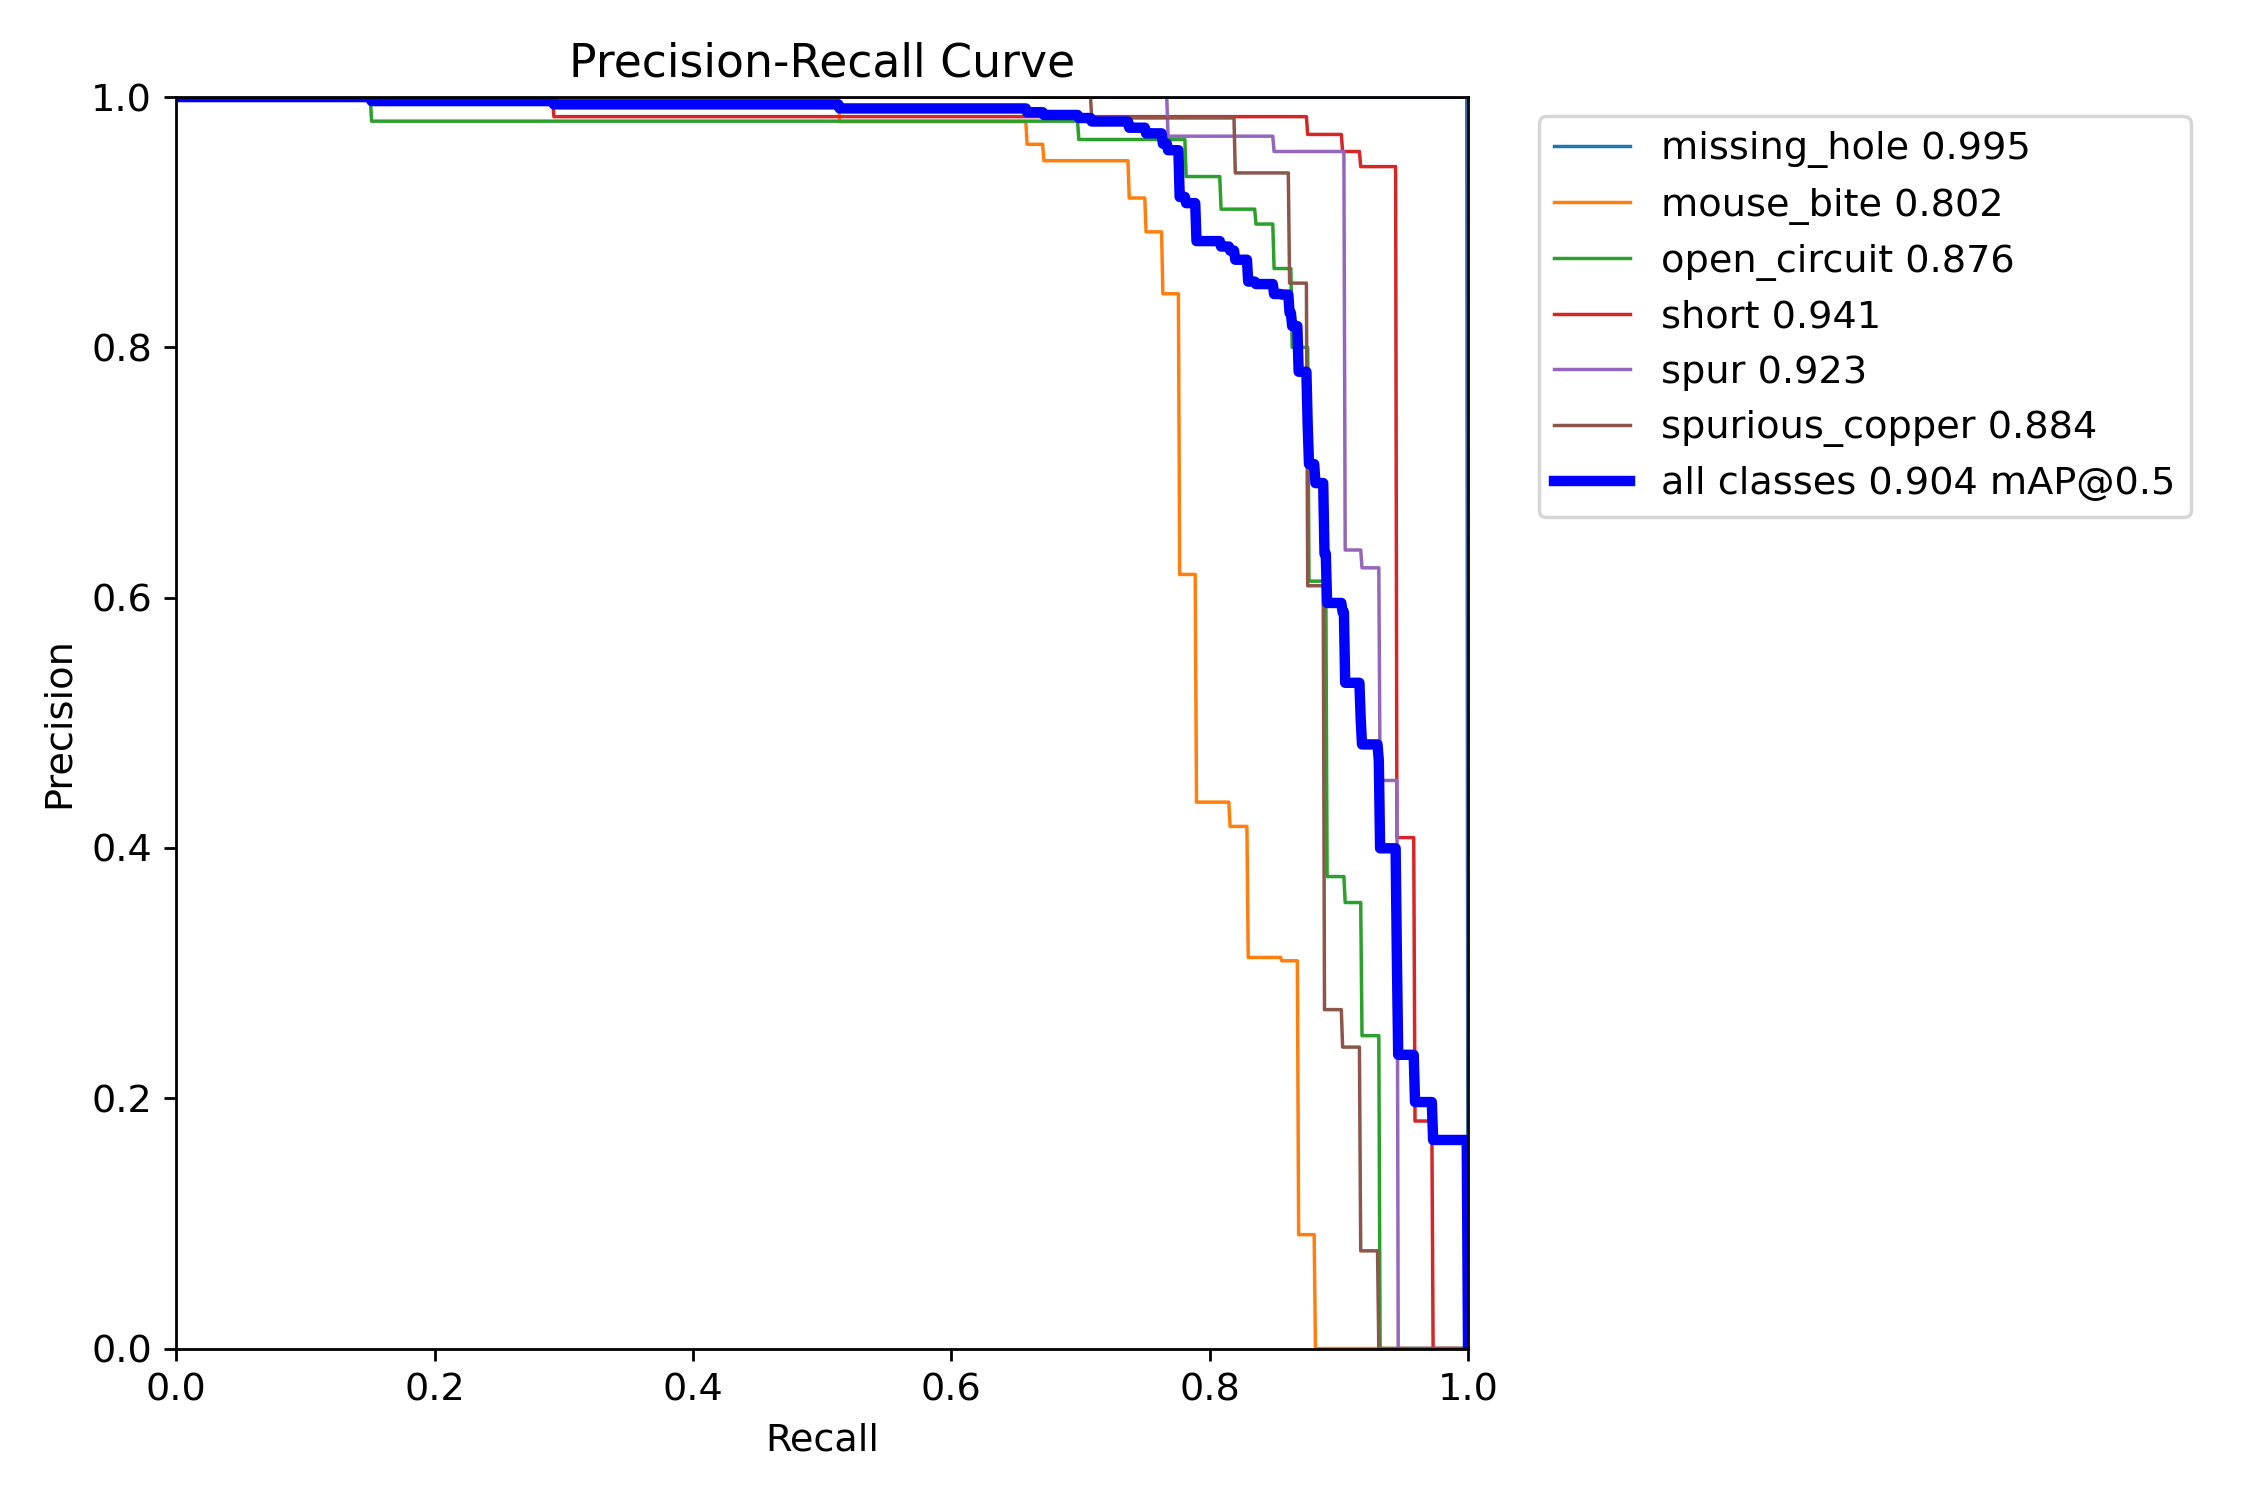

In [5]:
display(Image(filename=str(FIG / "03_pr_curve.png")))

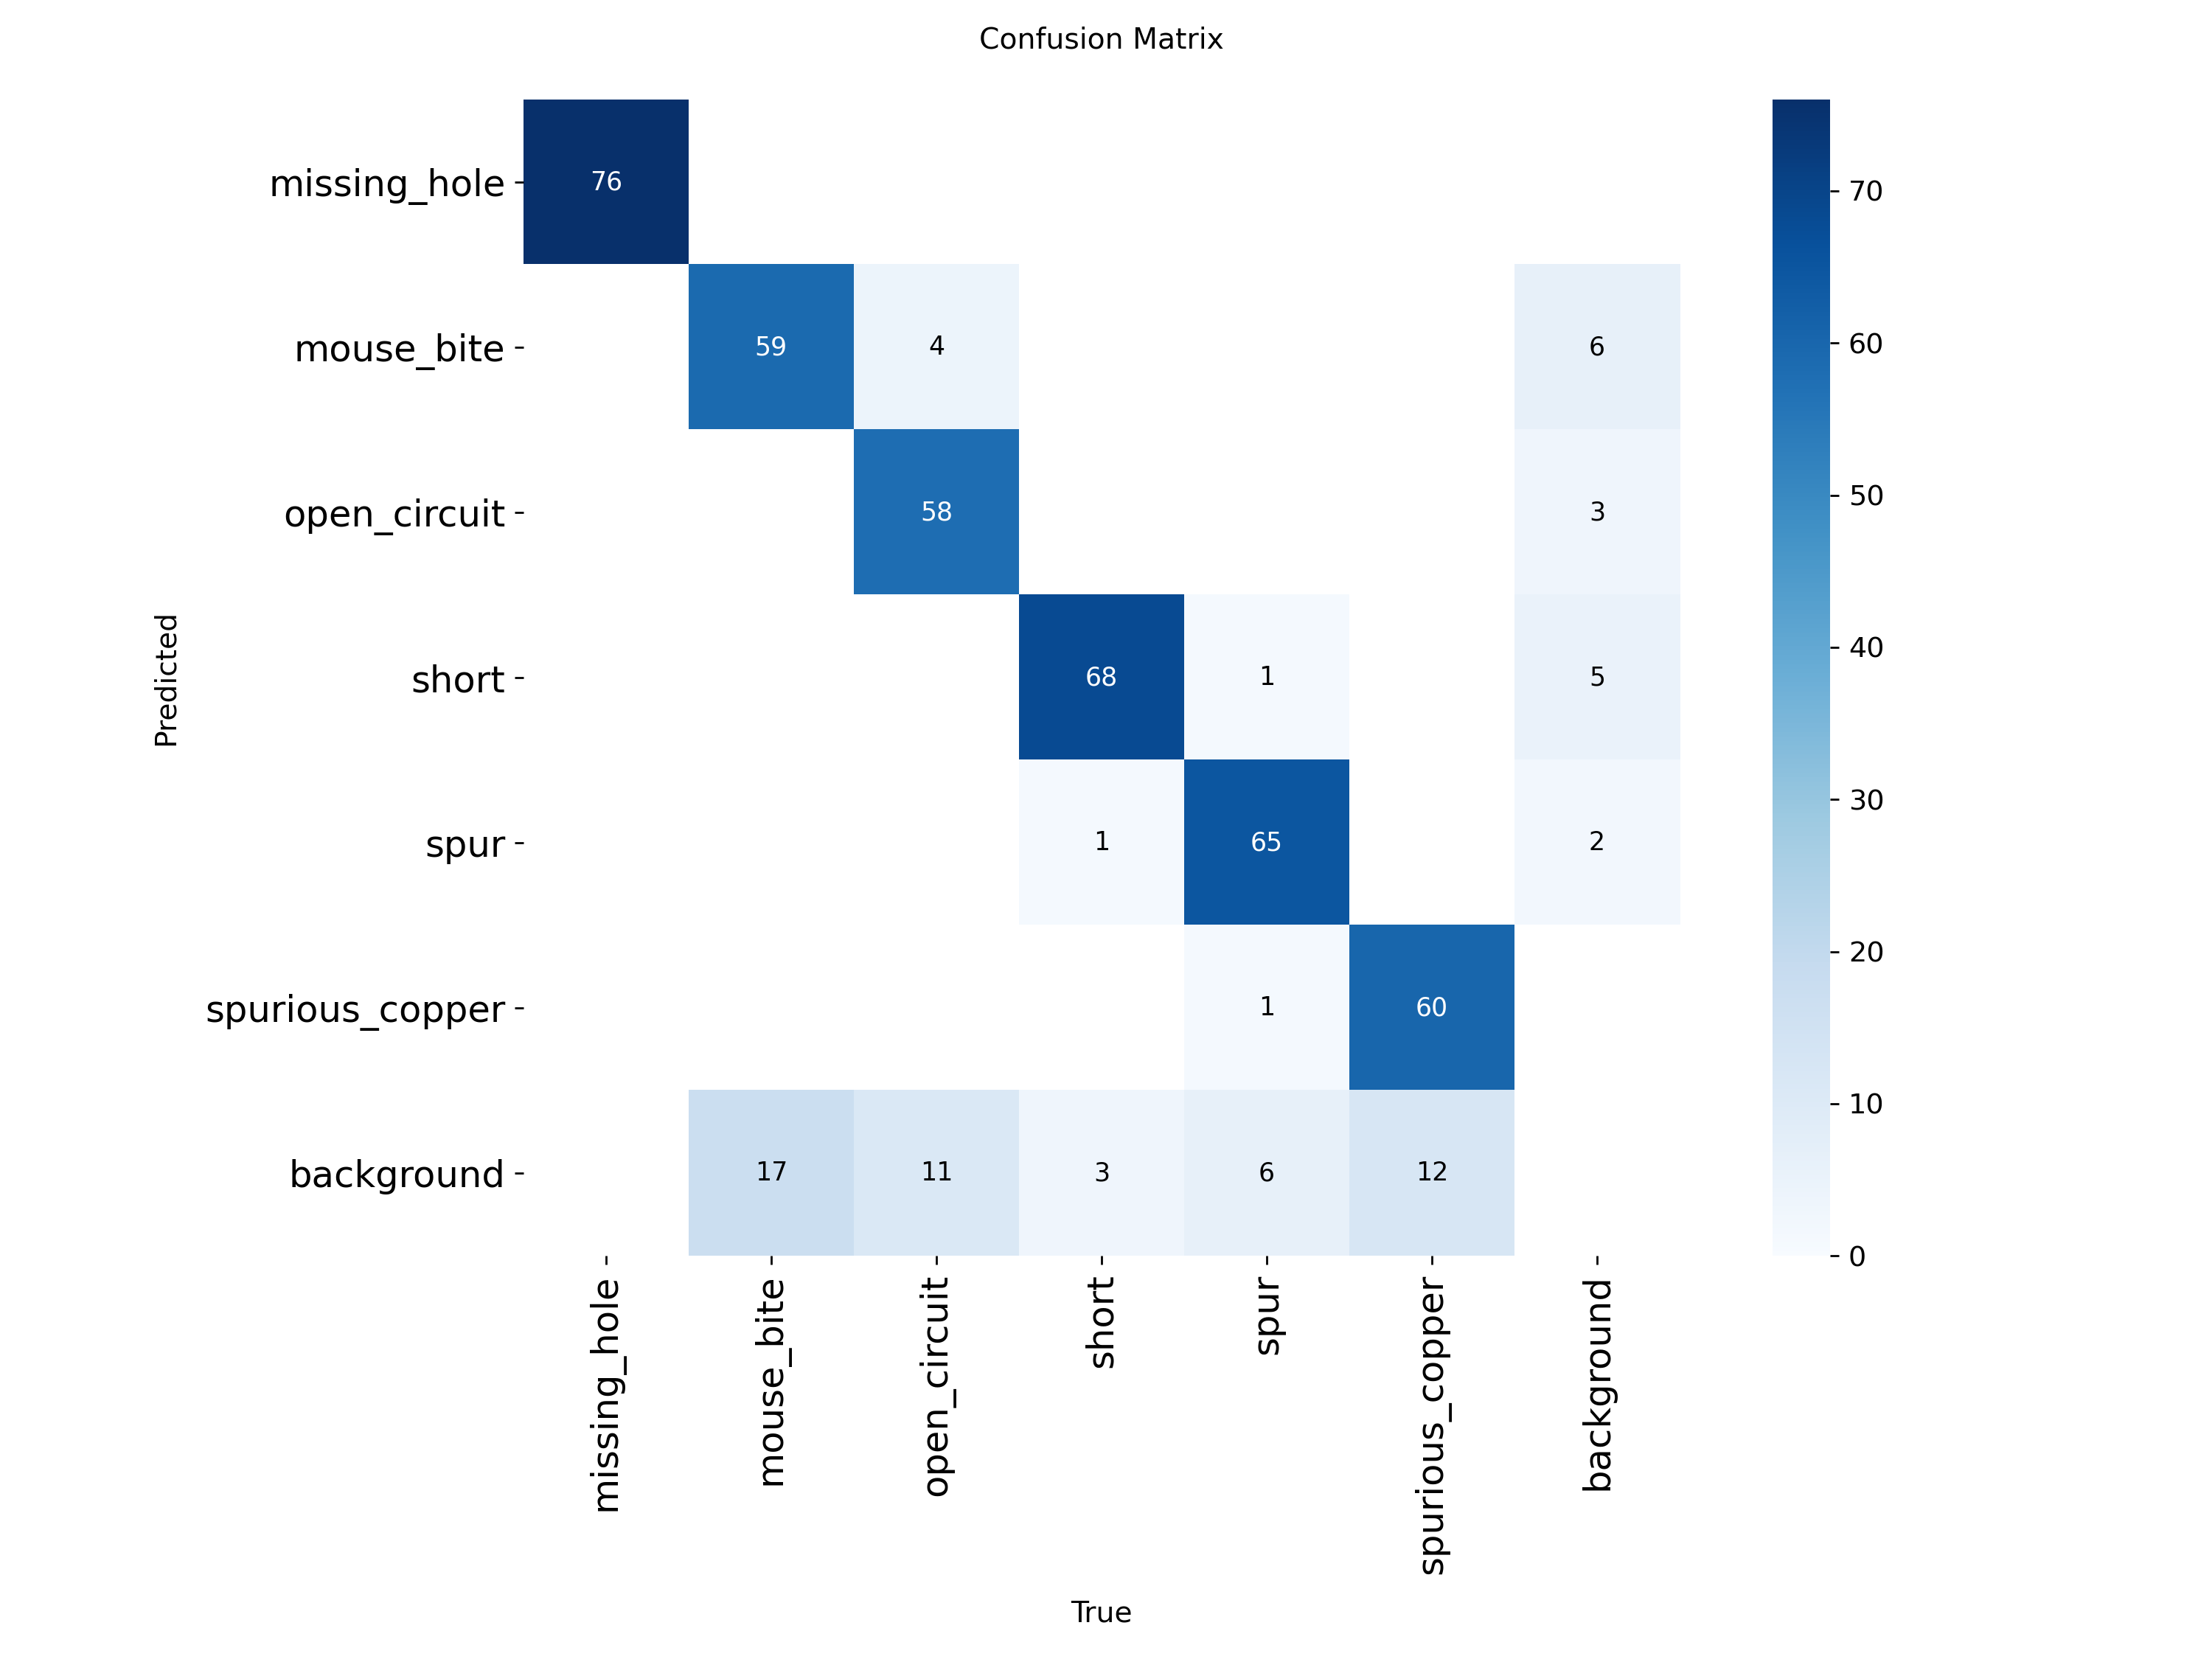

In [6]:
display(Image(filename=str(FIG / "03_confusion_matrix.png")))

### 3.2 三方法在同一張影像上的偵測結果(綠 = ground truth)

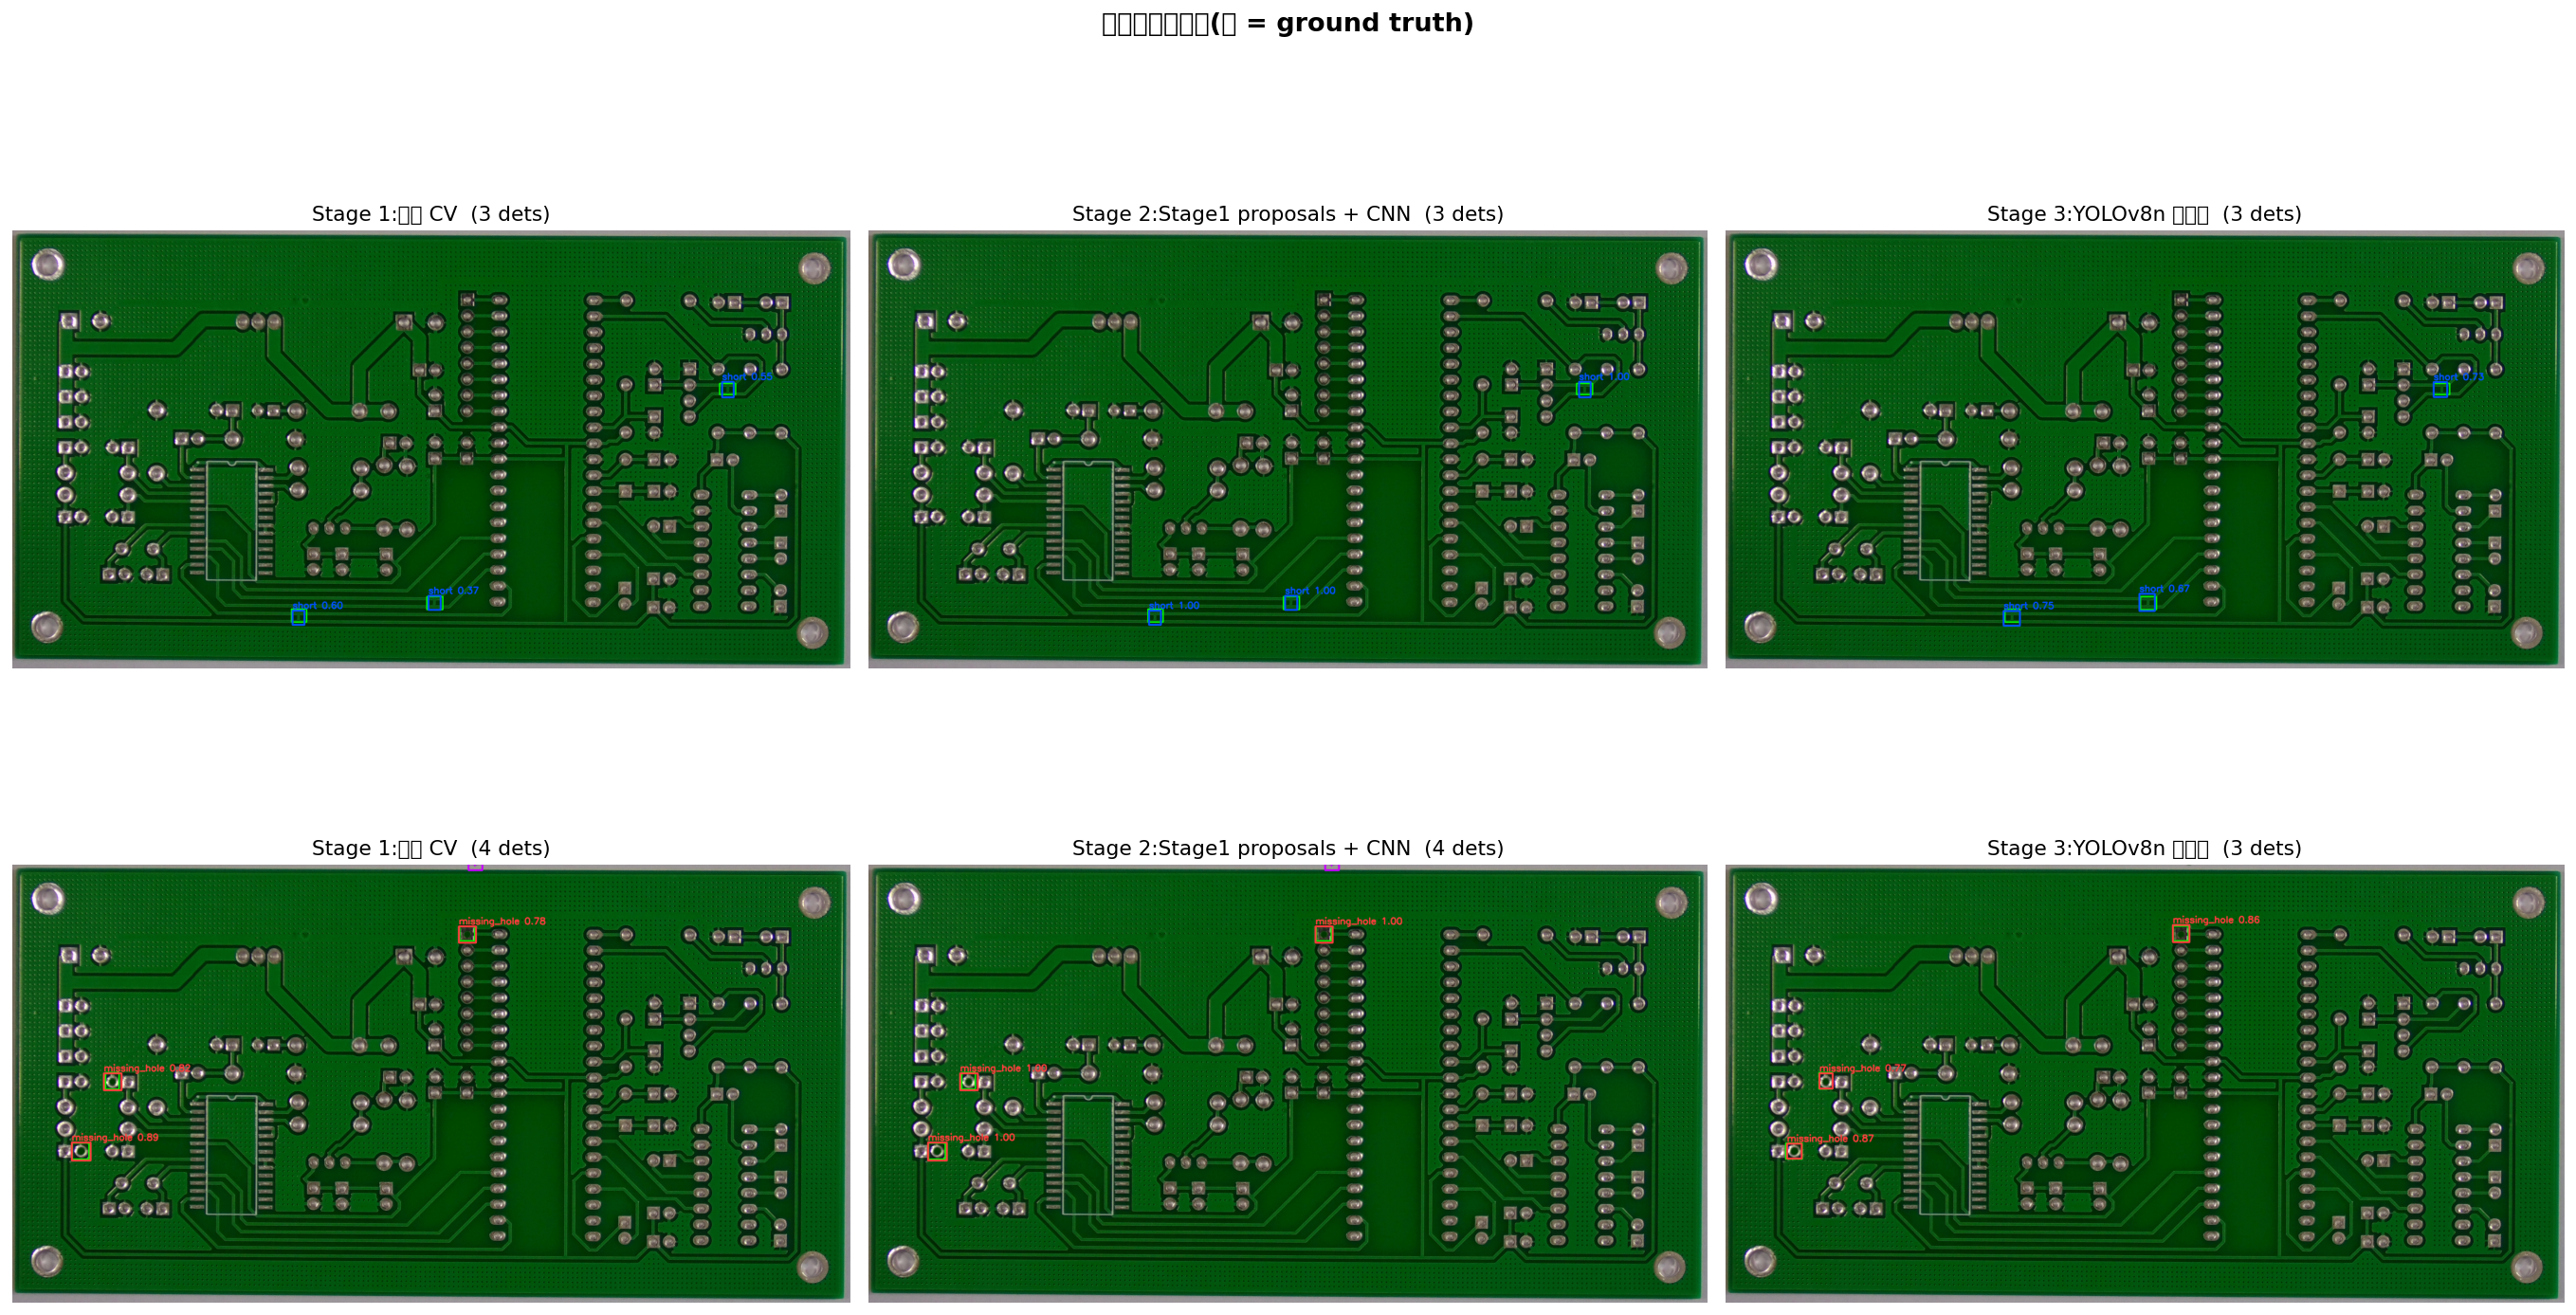

In [7]:
display(Image(filename=str(FIG / "03_three_methods_comparison.png")))

### 3.3 YOLO 樣本偵測

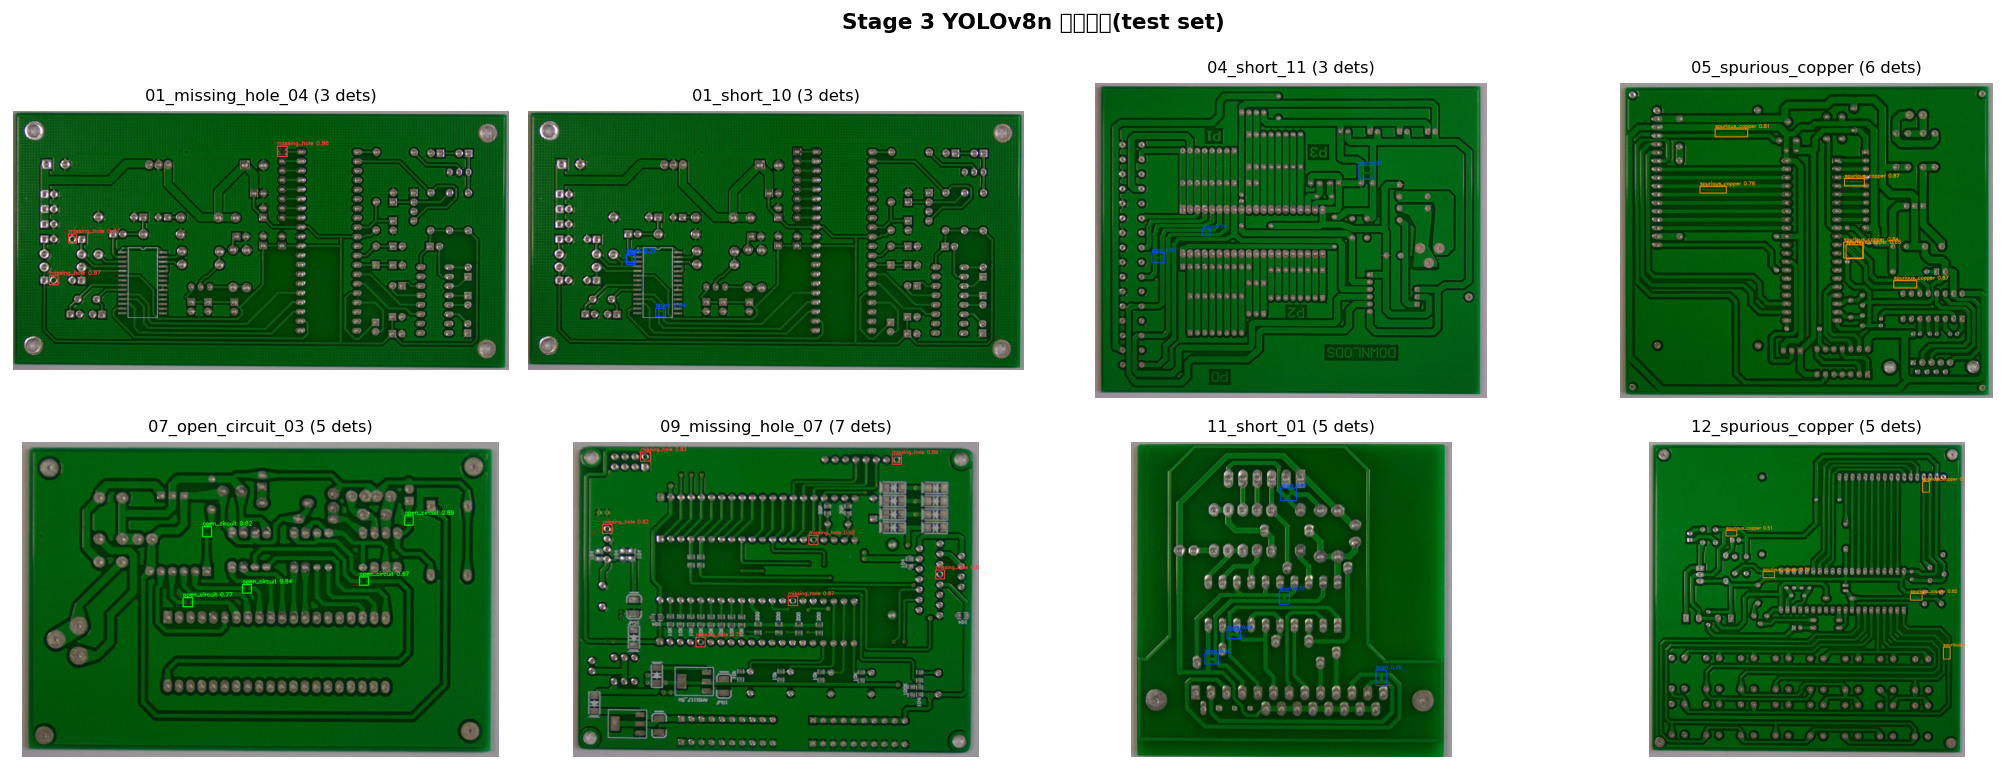

In [8]:
display(Image(filename=str(FIG / "03_sample_predictions.png")))

## 4. `short` 提升分析與失敗案例

完整分析見 [`results/yolo_report.md`](../results/yolo_report.md)。重點:`short` 從
Stage 1 的差影漏抓(AP 16–20%)、Stage 2 受 proposal recall 限制(36.2%),到
Stage 3 YOLO 端到端學習定位後的提升 —— 這驗證了瓶頸從「分類能力」轉移到
「proposal recall」,再由端到端架構突破。